[![Homepage](https://img.shields.io/badge/homepage-blueviolet?logo=htmx)](https://www.bendai.org/CUHK-STAT3009/)
[![GitHub](https://img.shields.io/badge/GitHub-black.svg?logo=github)](https://github.com/statmlben/CUHK-STAT3009)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/statmlben/CUHK-STAT3009/blob/main/nb/STAT3009_NCF.ipynb)

# Neural Collaborative Filtering

**STAT3009 · Recommender Systems**

> **Today:** turn user and item IDs into embeddings and learn the interaction with a small network. The Neural Networks warm-up lives in `STAT3009_NN.ipynb`; this notebook starts from the rating data.

**Route:** setup (3 min) → observed ratings (8 min) → MF as a network (12 min) → NCF (12 min) → additive NCF (10 min) → comparison (10 min) → practice (20 min) → extra practice (optional) → debrief (5 min).

## 1. Setup

We use PyTorch for the model and skorch as a thin sklearn-style wrapper. skorch gives us `fit`, `predict`, `history`, and `GridSearchCV` without changing the SGD update underneath.

In [1]:
import sys
import warnings

warnings.filterwarnings(
    'ignore', message='The given NumPy array is not writable'
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import skorch
import torch
from IPython.display import display
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import LabelEncoder
from skorch import NeuralNetRegressor
from skorch.dataset import ValidSplit
from torch import nn

pd.set_option('display.max_rows', 12)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
plt.rcParams['figure.dpi'] = 110

torch.manual_seed(0)
np.random.seed(0)

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('skorch:', skorch.__version__)
print('scikit-learn:', sklearn.__version__)
print('NumPy:', np.__version__)

Python: 3.13.3
PyTorch: 2.15.0
skorch: 1.4.0
scikit-learn: 1.9.1
NumPy: 2.5.5


## 2. The observed rating rows

A recommender takes a **user ID** and an **item ID**. The IDs are labels, not measurements: user 17 is not "twice" user 8.5. We need a layer that turns each ID into a learned vector.

We use the Netflix 1–5 star split in `dataset/netflix`. It has the same user–item pairs as the binary `b-rs` file used in the MF notebook, but keeps the original star ratings so RMSE is in stars.

In [2]:
RS_BASE_URL = (
    'https://raw.githubusercontent.com/'
    'statmlben/CUHK-STAT3009/main/dataset/netflix'
)
train = pd.read_csv(f'{RS_BASE_URL}/train.csv')
test = pd.read_csv(f'{RS_BASE_URL}/test.csv')

X_train_raw = train[['user_id', 'movie_id']].to_numpy()
X_test_raw = test[['user_id', 'movie_id']].to_numpy()
y_train = train['rating'].to_numpy(dtype=np.float32).reshape(-1, 1)
y_test = test['rating'].to_numpy(dtype=np.float32).reshape(-1, 1)

# Share one encoding across train and test pairs. No test ratings are used.
user_encoder = LabelEncoder().fit(
    np.concatenate([X_train_raw[:, 0], X_test_raw[:, 0]])
)
item_encoder = LabelEncoder().fit(
    np.concatenate([X_train_raw[:, 1], X_test_raw[:, 1]])
)
X_train = np.column_stack([
    user_encoder.transform(X_train_raw[:, 0]),
    item_encoder.transform(X_train_raw[:, 1]),
]).astype(np.float32)
X_test = np.column_stack([
    user_encoder.transform(X_test_raw[:, 0]),
    item_encoder.transform(X_test_raw[:, 1]),
]).astype(np.float32)

n_users = len(user_encoder.classes_)
n_items = len(item_encoder.classes_)
mu = float(y_train.mean())

print('training pairs:', X_train.shape)
print('test pairs:', X_test.shape)
print('users:', n_users, 'items:', n_items)
print('global mean rating:', f'{mu:.4f}')
print('possible pairs:', f'{n_users * n_items:,}',
      'observed training pairs:', f'{len(X_train):,}')
display(train.head())

training pairs: (51161, 2)
test pairs: (51161, 2)
users: 2000 items: 3568
global mean rating: 3.6212
possible pairs: 7,136,000 observed training pairs: 51,161


,movie_id,user_id,rating,date
0,670,1960,4,2004-02-10
1,152,1346,4,2003-02-15
2,1741,785,4,2005-06-15
3,3032,686,5,2004-05-09
4,536,1894,4,2005-07-10


**Only observed pairs enter the loss.** A missing user–item pair is not a rating of zero; it has no row in the training table. The test ratings are loaded here only because we will open them at the very end.

## 3. MF as a two-branch network

Matrix factorization is a tiny network with two embedding lookups and a dot product:

$$
\widehat r_{ui}=\mu+a_u+b_i+p_u^\top q_i.
$$

The embedding tables are `nn.Embedding`. The dot product is an elementwise product followed by a sum. Each table uses `max_norm=0.3`: the default random rows are too large for plain SGD, so the cap keeps the early dot products in a useful range. The bias terms are also `nn.Embedding` tables, with one scalar per ID, initialized to zero.

### The `nn.Embedding` API

Before the model, check the API directly. `nn.Embedding` stores a matrix

$$
W \in \mathbb{R}^{\text{num\_embeddings}\times\text{embedding\_dim}}.
$$

The input is an integer tensor of ID positions; the output appends one `embedding_dim` axis.

| input shape | output shape | example |
|---|---|---|
| `(B,)` | `(B,K)` | one user or item ID per row (NCF) |
| `(B,T)` | `(B,T,K)` | a sequence of token IDs (NLP) |

In [3]:
emb = nn.Embedding(num_embeddings=10, embedding_dim=4)
ids = torch.tensor([[1, 2], [3, 0]])   # (B,T) = (2,2), integer dtype
vectors = emb(ids)

print('weight shape:', tuple(emb.weight.shape))   # (10,4)
print('input shape: ', tuple(ids.shape))          # (2,2)
print('output shape:', tuple(vectors.shape))      # (2,2,4)
print('first sequence:')
print(vectors[0])

weight shape: (10, 4)
input shape:  (2, 2)
output shape: (2, 2, 4)
first sequence:
tensor([[ 0.8487,  0.6920, -0.3160, -2.1152],
        [ 0.3223, -1.2633,  0.3500,  0.3081]], grad_fn=<SelectBackward0>)


The lookup is exactly advanced indexing on `weight`:

In [4]:
print('same as weight[ids]:', torch.allclose(vectors, emb.weight[ids]))

same as weight[ids]: True


For NCF, the ID tensor is one-dimensional, so `user_emb(u)` returns `(B,K)`. The `(B,T)` case is the NLP pattern from the slides: a sequence of token IDs becomes a sequence of vectors.

In [5]:
class MFNet(nn.Module):
    def __init__(self, n_users, n_items, K=16, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        dot = (self.user_emb(u) * self.item_emb(i)).sum(dim=1, keepdim=True)
        return self.mu + self.user_bias(u) + self.item_bias(i) + dot


mf_demo = MFNet(n_users, n_items)
print(mf_demo)
print('learned numbers:', sum(p.numel() for p in mf_demo.parameters()))
print('output shape:', tuple(mf_demo(torch.as_tensor(X_train[:5])).shape))

MFNet(
  (user_emb): Embedding(2000, 16, max_norm=0.3)
  (item_emb): Embedding(3568, 16, max_norm=0.3)
  (user_bias): Embedding(2000, 1)
  (item_bias): Embedding(3568, 1)
)
learned numbers: 94657
output shape: (5, 1)


The first five rows produce five scores, shape `(5,1)`. Each ID selects one row from its table; training updates the table entries. `K` is a hyperparameter chosen before fitting.

## 4. NCF: embeddings plus a learned interaction

NCF replaces the fixed dot product with a small MLP:

$$
\widehat r_{ui}=\mu+a_u+b_i+g_\theta([p_u,q_i]).
$$

`torch.cat` concatenates the two `(B,K)` embeddings into `(B,2K)`. The MLP then learns the interaction.

In [6]:
class BiasedNCF(nn.Module):
    def __init__(self, n_users, n_items, K=16, hidden=32, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))
        self.net = nn.Sequential(
            nn.Linear(2 * K, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        z = torch.cat([self.user_emb(u), self.item_emb(i)], dim=1)
        return self.mu + self.user_bias(u) + self.item_bias(i) + self.net(z)


ncf_demo = BiasedNCF(n_users, n_items)
print(ncf_demo)
print('learned numbers:', sum(p.numel() for p in ncf_demo.parameters()))
print('output shape:', tuple(ncf_demo(torch.as_tensor(X_train[:5])).shape))

BiasedNCF(
  (user_emb): Embedding(2000, 16, max_norm=0.3)
  (item_emb): Embedding(3568, 16, max_norm=0.3)
  (user_bias): Embedding(2000, 1)
  (item_bias): Embedding(3568, 1)
  (net): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
learned numbers: 96258
output shape: (5, 1)


**Checkpoint.** What is the shape of `self.user_emb(u)`? What is the shape after `torch.cat`? Why must the two embeddings have the same width `K`?

## 5. Additive NCF: keep MF and add a correction

Additive NCF keeps the dot-product path and adds a separate neural path:

$$
\widehat r_{ui}=\mu+a_u+b_i+p_u^\top q_i+h_\phi([s_u,t_i]).
$$

The dot product captures the simple matching pattern; the MLP can model structured residuals.

In [7]:
class ANCF(nn.Module):
    def __init__(self, n_users, n_items, K=16, R=8, hidden=32, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_neural = nn.Embedding(n_users, R, max_norm=0.3)
        self.item_neural = nn.Embedding(n_items, R, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))
        self.net = nn.Sequential(
            nn.Linear(2 * R, hidden), nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        mf = (self.user_emb(u) * self.item_emb(i)).sum(dim=1, keepdim=True)
        z = torch.cat([self.user_neural(u), self.item_neural(i)], dim=1)
        return self.mu + self.user_bias(u) + self.item_bias(i) + mf + self.net(z)


ancf_demo = ANCF(n_users, n_items)
print('learned numbers:', sum(p.numel() for p in ancf_demo.parameters()))
print('output shape:', tuple(ancf_demo(torch.as_tensor(X_train[:5])).shape))

learned numbers: 139778
output shape: (5, 1)


## 6. Train and compare

The training recipe is the same for all three models: MSE, SGD with learning rate `0.05`, batch size `256`, 50 epochs, and a fixed 10% validation split. We pin the seed inside each model class so the folds and the final refit are reproducible.

Each `NeuralNetRegressor` below writes out the same settings, so every value is visible where it is used.

In [8]:
mf = NeuralNetRegressor(
    module=MFNet,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
mf.fit(X_train, y_train)

ncf = NeuralNetRegressor(
    module=BiasedNCF,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
ncf.fit(X_train, y_train)

ancf = NeuralNetRegressor(
    module=ANCF,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
ancf.fit(X_train, y_train)

models = {
    'Biased MF': mf,
    'Biased NCF': ncf,
    'Additive NCF': ancf,
}
print('trained:', list(models))

trained: ['Biased MF', 'Biased NCF', 'Additive NCF']


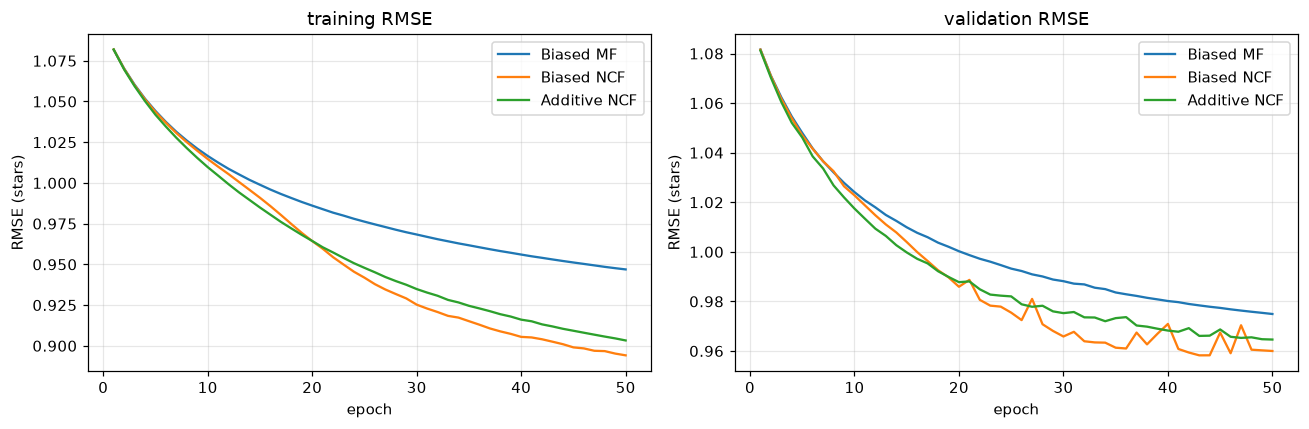

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, model in models.items():
    epochs = np.arange(1, len(model.history) + 1)
    axes[0].plot(epochs, np.sqrt(model.history[:, 'train_loss']), label=name)
    axes[1].plot(epochs, np.sqrt(model.history[:, 'valid_loss']), label=name)
for ax, title in zip(axes, ['training RMSE', 'validation RMSE']):
    ax.set_xlabel('epoch')
    ax.set_ylabel('RMSE (stars)')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        'model': name,
        'parameters': sum(p.numel() for p in model.module_.parameters()),
        'train RMSE': np.sqrt(model.history[-1, 'train_loss']),
        'validation RMSE': np.sqrt(model.history[-1, 'valid_loss']),
        'test RMSE': root_mean_squared_error(y_test, pred),
    })

comparison = pd.DataFrame(rows).set_index('model')
display(comparison.round(4))

,parameters,train RMSE,validation RMSE,test RMSE
model,,,,
Biased MF,94657,0.9469,0.9749,0.9712
Biased NCF,96258,0.8941,0.9600,0.9568
Additive NCF,139778,0.9033,0.9646,0.9592


**Discuss.** Which model wins on validation? Does the test ranking agree? The training curves fall together, but the validation curves separate. More flexibility is not automatically better: the embedding tables are large and the observed ratings are sparse.

## 7. In-class practice

Work in pairs for 20 minutes.

1. Fit `BiasedNCF` with `K=8` and `hidden=16`. Compare validation and test RMSE with the `K=16, hidden=32` version.
2. Fit a wider version with `K=16, hidden=64`. Does validation improve?
3. Run the small `GridSearchCV` below over `K` and `hidden`. Use `train_split=False`, `cv=3`, and `refit=True`. The search uses 30 epochs to keep the classroom run fast; the comparison above uses 50.
4. Report the best settings and the test RMSE of `gs_ncf.best_estimator_`.

Remember: choose on validation, then open the test set once.

In [11]:
practice_small = NeuralNetRegressor(
    module=BiasedNCF,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    module__K=8,
    module__hidden=16,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
practice_small.fit(X_train, y_train)

practice_wide = NeuralNetRegressor(
    module=BiasedNCF,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    module__K=16,
    module__hidden=64,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
practice_wide.fit(X_train, y_train)

for name, model in [('K=8, hidden=16', practice_small),
                    ('K=16, hidden=64', practice_wide)]:
    pred = model.predict(X_test)
    print(f'{name:18s} validation RMSE '
          f"{np.sqrt(model.history[-1, 'valid_loss']):.4f} "
          f'test RMSE {root_mean_squared_error(y_test, pred):.4f}')

K=8, hidden=16     validation RMSE 0.9746 test RMSE 0.9710


K=16, hidden=64    validation RMSE 0.9708 test RMSE 0.9657


### Solution: a small grid over `K` and `hidden`

`GridSearchCV` supplies the validation folds, so we turn off skorch's internal split. `refit=True` refits the winner on all training rows.

In [12]:
search_ncf = NeuralNetRegressor(
    module=BiasedNCF,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=30,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=False,
    verbose=0,
)

param_grid_ncf = {
    'module__K': [8, 16],
    'module__hidden': [16, 32],
}

gs_ncf = GridSearchCV(
    search_ncf, param_grid_ncf,
    cv=3, scoring='neg_root_mean_squared_error',
    refit=True,
)
gs_ncf.fit(X_train, y_train)

print('best settings:', gs_ncf.best_params_)
print('best CV RMSE:', f'{-gs_ncf.best_score_:.4f}')
print('test RMSE:',
      f'{root_mean_squared_error(y_test, gs_ncf.best_estimator_.predict(X_test)):.4f}')

cv_table = pd.DataFrame({
    'K': [int(v) for v in gs_ncf.cv_results_['param_module__K']],
    'hidden': [int(v) for v in gs_ncf.cv_results_['param_module__hidden']],
    'CV RMSE': -gs_ncf.cv_results_['mean_test_score'],
    'CV std': gs_ncf.cv_results_['std_test_score'],
}).sort_values('CV RMSE').reset_index(drop=True)

display(cv_table.round(4))

best settings: {'module__K': 16, 'module__hidden': 32}
best CV RMSE: 0.9802


test RMSE: 0.9576


,K,hidden,CV RMSE,CV std
0,16,32,0.9802,0.0077
1,16,16,0.9918,0.0060
2,8,32,0.9941,0.0065
3,8,16,0.9949,0.0060


**Discuss.** Did the grid choose the same model as the manual comparison? Why might the CV ranking differ from the single validation-split ranking?

## 8. Extra practice: more two-branch models

All of these keep the same two embedding branches. Only the **merge** changes.

| model | merge | head |
|---|---|---|
| Biased MF | dot product | none |
| Biased NCF | concatenate | MLP |
| GMF | elementwise product | linear |
| Two-tower | separate MLPs, then dot | none |
| NeuMF | GMF vector + MLP vector | linear |

The skeletons below leave the merge for you to complete. The solutions use the same explicit settings, so the training and validation recipe is unchanged.

### Exercise A: GMF — learn the head

GMF keeps the elementwise product but learns a weight for each factor:

$$
\widehat r_{ui}=\mu+a_u+b_i+w^\top(p_u\odot q_i).
$$

Complete `forward`, then fit the model with `NeuralNetRegressor`.

In [13]:
class GMF(nn.Module):
    def __init__(self, n_users, n_items, K=16, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))
        self.head = nn.Linear(K, 1)

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        # product = ...
        # return ...
        ...

### Solution

In [14]:
class GMF(nn.Module):
    def __init__(self, n_users, n_items, K=16, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))
        self.head = nn.Linear(K, 1)

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        product = self.user_emb(u) * self.item_emb(i)
        return self.mu + self.user_bias(u) + self.item_bias(i) + self.head(product)


gmf = NeuralNetRegressor(
    module=GMF,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
gmf.fit(X_train, y_train)
gmf_pred = gmf.predict(X_test)
print('GMF validation RMSE:',
      f"{np.sqrt(gmf.history[-1, 'valid_loss']):.4f}")
print('GMF test RMSE:', f'{root_mean_squared_error(y_test, gmf_pred):.4f}')

GMF validation RMSE: 0.9747
GMF test RMSE: 0.9714


### Exercise B: two-tower — separate MLPs

Give the user and the item their own small MLP, then take the dot product of the
two encoded vectors:

$$
\widehat r_{ui}=\mu+a_u+b_i+f_u(p_u)^\top f_i(q_i).
$$

Complete the two towers and the merge.

In [15]:
class TwoTower(nn.Module):
    def __init__(self, n_users, n_items, K=16, hidden=32, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))
        self.user_tower = nn.Sequential(
            nn.Linear(K, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
        )
        self.item_tower = nn.Sequential(
            nn.Linear(K, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
        )

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        pu = self.user_tower(self.user_emb(u))
        qi = self.item_tower(self.item_emb(i))
        # return ...
        ...

### Solution

In [16]:
class TwoTower(nn.Module):
    def __init__(self, n_users, n_items, K=16, hidden=32, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))
        self.user_tower = nn.Sequential(
            nn.Linear(K, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
        )
        self.item_tower = nn.Sequential(
            nn.Linear(K, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
        )

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        pu = self.user_tower(self.user_emb(u))
        qi = self.item_tower(self.item_emb(i))
        dot = (pu * qi).sum(dim=1, keepdim=True)
        return self.mu + self.user_bias(u) + self.item_bias(i) + dot


two_tower = NeuralNetRegressor(
    module=TwoTower,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
two_tower.fit(X_train, y_train)
two_tower_pred = two_tower.predict(X_test)
print('Two-tower validation RMSE:',
      f"{np.sqrt(two_tower.history[-1, 'valid_loss']):.4f}")
print('Two-tower test RMSE:',
      f'{root_mean_squared_error(y_test, two_tower_pred):.4f}')

Two-tower validation RMSE: 0.9613
Two-tower test RMSE: 0.9588


### Optional challenge: NeuMF

NeuMF keeps two parallel paths: a GMF vector and an MLP vector. Concatenate them
and pass the result through a final linear layer:

$$
\widehat r_{ui}=\mu+a_u+b_i+w^\top\bigl[\,p_u\odot q_i,\;\psi([s_u,t_i])\,\bigr].
$$

This is a capstone exercise; run it if you have time.

In [17]:
class NeuMF(nn.Module):
    def __init__(self, n_users, n_items, K=16, R=8, hidden=32, mu=0.0):
        super().__init__()
        torch.manual_seed(0)
        self.user_emb = nn.Embedding(n_users, K, max_norm=0.3)
        self.item_emb = nn.Embedding(n_items, K, max_norm=0.3)
        self.user_neural = nn.Embedding(n_users, R, max_norm=0.3)
        self.item_neural = nn.Embedding(n_items, R, max_norm=0.3)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)
        self.mu = nn.Parameter(torch.tensor([mu]))
        self.mlp = nn.Sequential(
            nn.Linear(2 * R, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
        )
        self.head = nn.Linear(K + hidden // 2, 1)

    def forward(self, x):
        u = x[:, 0].long()
        i = x[:, 1].long()
        gmf = self.user_emb(u) * self.item_emb(i)
        mlp = self.mlp(
            torch.cat([self.user_neural(u), self.item_neural(i)], dim=1)
        )
        z = torch.cat([gmf, mlp], dim=1)
        return self.mu + self.user_bias(u) + self.item_bias(i) + self.head(z)


neumf = NeuralNetRegressor(
    module=NeuMF,
    module__n_users=n_users,
    module__n_items=n_items,
    module__mu=mu,
    criterion=nn.MSELoss,
    optimizer=torch.optim.SGD,
    optimizer__lr=0.05,
    max_epochs=50,
    batch_size=256,
    iterator_train__shuffle=True,
    train_split=ValidSplit(0.1, random_state=0),
    verbose=0,
)
neumf.fit(X_train, y_train)
neumf_pred = neumf.predict(X_test)
print('NeuMF validation RMSE:',
      f"{np.sqrt(neumf.history[-1, 'valid_loss']):.4f}")
print('NeuMF test RMSE:',
      f'{root_mean_squared_error(y_test, neumf_pred):.4f}')

NeuMF validation RMSE: 0.9687
NeuMF test RMSE: 0.9623


**Discuss.** Did the extra branches improve validation? The two-tower is competitive, but NeuMF needs more tuning. More branches are not automatically better; compare validation curves and keep the test set closed.

## 9. Failure patterns and rules of thumb

| symptom | likely cause | next check |
|---|---|---|
| loss oscillates | learning rate too large | reduce the step size |
| loss hardly moves | learning rate too small | increase the step size |
| training improves, validation worsens | overfitting | smaller `K`, fewer epochs, more data |
| validation is excellent but test is poor | leakage or a lucky split | audit the split and encoding |
| shape error at the first batch | IDs are not integer/long | print `x.dtype` and `x.shape` |
| embedding index out of range | encoder and model disagree | check `n_users` and `n_items` |

| choice | starting point |
|---|---|
| embedding size `K` | 8–32 for a small course dataset |
| hidden width | 16–64; halve the next layer |
| activation | ReLU |
| epochs | 30–50; choose by validation |
| batch size | 64–256 |
| optimizer | vanilla SGD; start at `lr=0.05` |

These are starting points, not laws. Tune one thing at a time and compare validation curves.

## Exit ticket

Answer each question in one or two sentences.

1. Why can an embedding layer be viewed as a one-hot matrix product?
2. What does `torch.cat` do in NCF, and what is the resulting shape?
3. What changes from MF to NCF, and what stays the same?
4. Why must the validation set stay out of the gradient updates?
5. What happens when a user or item ID was never seen during training?
6. Why might MF beat NCF on a sparse dataset?

## Summary

```text
(train pairs, test pairs)
  → LabelEncoder
  → nn.Embedding(n_users, K), nn.Embedding(n_items, K)
  → torch.cat([p_u, q_i])          # shape (B,2K)
  → nn.Sequential(Linear, ReLU, Linear)
  → rating score
  → MSE + SGD
  → validation curve + GridSearchCV
```

NCF changes only the **data representation** (IDs become embeddings) and the **interaction** (a dot product becomes a learned MLP). The four questions do not change. Check shapes before training, choose with validation, and open the test set once.

Next: use side information to build representations for new users and items.

## References

- PyTorch `nn.Embedding`: <https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html>
- PyTorch `torch.cat`: <https://pytorch.org/docs/stable/generated/torch.cat.html>
- PyTorch `nn.Linear`: <https://pytorch.org/docs/stable/generated/torch.nn.Linear.html>
- PyTorch `nn.Module`: <https://pytorch.org/docs/stable/generated/torch.nn.Module.html>
- PyTorch SGD: <https://pytorch.org/docs/stable/generated/torch.optim.SGD.html>
- skorch `NeuralNetRegressor`: <https://skorch.readthedocs.io/en/stable/regressor.html>
- scikit-learn `GridSearchCV`: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html>
- NCF paper: <https://arxiv.org/abs/1708.05031>